# Preparación del entorno

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# Ejercicio 2


In [2]:
from pathlib import Path

# Buscar datasets/ desde la raíz del proyecto o desde notebooks/.
project_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "datasets").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "No se encontró datasets/. Abrí el notebook dentro del proyecto "
        "y conservá la carpeta datasets/ junto a notebooks/."
    )
dataset_dir = project_root / "datasets" / "ej2"
print("Datos locales:", dataset_dir)


Datos locales: /home/thiago/fiuba/cdd/tp1/datasets/ej2


In [3]:
# Cargamos todos los archivos
ds_listings=pd.read_csv(dataset_dir / 'listings.csv.gz')
ds_listings_trabajo=ds_listings.copy()

In [4]:
ds_listings_trabajo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25750 entries, 0 to 25749
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            25750 non-null  int64  
 1   listing_url                                   25750 non-null  object 
 2   scrape_id                                     25750 non-null  int64  
 3   last_scraped                                  25750 non-null  object 
 4   source                                        25750 non-null  object 
 5   name                                          25750 non-null  object 
 6   description                                   25280 non-null  object 
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   25750 non-null  object 
 9   host_id                                       25750 non-null 

In [5]:
ds_listings_trabajo.shape

(25750, 90)

## Análisis de valores faltantes

Primero veremos columnas tienen valores nulos, y luego veremos como tratar cada uno de ellos.

In [6]:
pd.set_option("display.max_rows", 30)
ds_listings_trabajo.isnull().sum()[ds_listings_trabajo.isnull().sum() > 0]

description                 470
neighborhood_overview     25750
host_since                25750
host_location              5575
host_about                11803
                          ...  
review_scores_location     3824
review_scores_value        3825
license                    3251
instant_bookable          25750
reviews_per_month          3824
Length: 45, dtype: int64

Observamos ciertas variables que no contienen información para ninguna fila de observaciones (neighborhood_overview, host_since), ya que cuentan con 25750 valores nulos, y esta es la cantidad de filas que existen en la tabla. Por esta razón, eliminaremos estas columnas ya que no aportarían nada al análisis.

In [7]:
ds_listings_trabajo = ds_listings_trabajo.dropna(axis=1, how="all")

Tambien se cuenta con 2813 filas sin precio, y decidimos eliminarlas ya que no nos permiten entrenar el modelo ni testearlo.

In [8]:
ds_listings_trabajo = ds_listings_trabajo.dropna(subset=["price"])

### Reviews

3320 alojamientos no poseen reviews y se deben imputar esos campos. Para iniciar, creamos la nueva variable has_reviews que nos va a ayudar a entrenar al modelo.

In [9]:
ds_listings_trabajo["has_reviews"] = ds_listings_trabajo["number_of_reviews"] > 0

#### Reviews per month

In [10]:
(ds_listings_trabajo["reviews_per_month"] == 0).sum()

np.int64(0)

In [11]:
tabla = pd.crosstab(
    ds_listings_trabajo["reviews_per_month"].isnull(),
    ds_listings_trabajo["number_of_reviews"] == 0,
    rownames=["reviews_per_month"],
    colnames=["number_of_reviews"],
    normalize="index"
).mul(100).round(1)

tabla = tabla.rename(
    index={False: "Con valor", True: "Nulo"},
    columns={False: "Tiene reseñas (> 0)", True: "Sin reseñas (= 0)"}
)
tabla

number_of_reviews,Tiene reseñas (> 0),Sin reseñas (= 0)
reviews_per_month,,
Con valor,100.0,0.0
Nulo,0.0,100.0


La columna 'reviews_per_month' es la que posee más valores nulos. Como se puede evidenciar, no hay ninguna fila que tenga reviews_per_month = 0, por ello empezamos un análisis para determinar si los nulos equivaldrían a 0. Decidimos comparar con la columna 'number_of_reviews' y quedó demostrado que cuando esa columna vale 0, las reviews son nulas, por lo tanto sería adecuado completar con 0 los valores nulos.

In [12]:
ds_listings_trabajo["reviews_per_month"] = (
    ds_listings_trabajo["reviews_per_month"].fillna(0)
)

#### First y Last Review

In [13]:
# Convertir fechas
ds_listings_trabajo["last_scraped"] = pd.to_datetime(ds_listings_trabajo["last_scraped"])
ds_listings_trabajo["first_review"] = pd.to_datetime(ds_listings_trabajo["first_review"])
ds_listings_trabajo["last_review"] = pd.to_datetime(ds_listings_trabajo["last_review"])

# Días desde la primera y última review
ds_listings_trabajo["days_since_first_review"] = (
    ds_listings_trabajo["last_scraped"] - ds_listings_trabajo["first_review"]
).dt.days

ds_listings_trabajo["days_since_last_review"] = (
    ds_listings_trabajo["last_scraped"] - ds_listings_trabajo["last_review"]
).dt.days

# -1 representa que nunca tuvo reviews
ds_listings_trabajo["days_since_first_review"] = ds_listings_trabajo["days_since_first_review"].fillna(-1)
ds_listings_trabajo["days_since_last_review"] = ds_listings_trabajo["days_since_last_review"].fillna(-1)

Creamos las nuevas columnas 'days_since_first_review' y 'days_since_last_review' y rellenamos las filas sin reviews con -1 en estos campos. Consideramos que era una mejor alternativa a poner una fecha seteada y que estos nuevos campos son mas útiles para el análisis de las observaciones. Por ejemplo, 'days_since_last_review' podría ser un indicador de si un alojamiento es alquilado frecuentemente o si esta inactivo.

### Host location
Para manejar los NaN de host_location proponemos 2 alternativas: Agrupar en las categorias de Milan, Rest of Italy, Foreign y Unknown, o separar en Milan, Rest of Italy, Unknown y ademas cada pais en otra categoria, donde para solucionar categorias muy raras (*que* tengan apenas algunos pocos hosts), juntarlos en una categoria de "Other".

#### Opcion 1: Agrupar en Milan, Italia, Extranjero y Desconocido

In [14]:
def agrupar_host_location(location):
    if pd.isna(location):
        return "Unknown"

    if location == "Milan, Italy":
        return "Milan"

    if "Italy" in location:
        return "Rest of Italy"

    return "Foreign"

ds_listings_trabajo_clon = ds_listings_trabajo.copy()
ds_listings_trabajo_clon["host_location"] = (
    ds_listings_trabajo_clon["host_location"].apply(agrupar_host_location)
)

#### Opcion 2: Agrupar por pais con umbral

In [15]:
def agrupar_host_location_pais(location):
    if pd.isna(location):
        return "Unknown"

    if location == "Milan, Italy":
        return "Milan"

    # Tomamos como país la última parte
    return location.split(",")[-1].strip()


ds_listings_trabajo["host_location"] = (
    ds_listings_trabajo["host_location"]
    .apply(agrupar_host_location_pais)
)

# El umbral de frecuencia se aplica después de separar train/test,
# usando únicamente las categorías observadas en entrenamiento.


Ahora con cualquiera de las 2 alternativas vemos como quedo este campo:

In [16]:
ds_listings_trabajo["host_location"].value_counts(dropna=False)

host_location
Milan             16062
Unknown            4932
Italy              1524
Other               196
Switzerland          72
United Kingdom       59
Spain                39
France               31
Austria              22
Name: count, dtype: int64

### Bathrooms

Primero se analizaron los registros con valores faltantes en bathrooms y su relación con otras características del alojamiento:

In [17]:
ds_listings_trabajo[ds_listings_trabajo["bathrooms"].isna()][["room_type", "property_type", "accommodates", "bedrooms", "beds"]].head()

,room_type,property_type,accommodates,bedrooms,beds
20,Entire home/apt,Entire condo,2,2.0,NaN
39,Entire home/apt,Entire rental unit,2,1.0,NaN
53,Entire home/apt,Entire rental unit,2,1.0,1.0
56,Private room,Private room in home,2,NaN,1.0
77,Entire home/apt,Entire rental unit,4,2.0,NaN


También se estudió la distribución de bathrooms según el tipo de habitación:

In [18]:
ds_listings_trabajo.groupby("room_type")["bathrooms"].agg(["count", "median", "mean", "min", "max"])

,count,median,mean,min,max
room_type,,,,,
Entire home/apt,19067,1.0,1.168931,0.5,10.0
Hotel room,18,1.0,1.000000,1.0,1.0
Private room,2236,1.0,1.127460,0.5,21.0
Shared room,51,1.0,1.411765,1.0,4.0


Se observó que la mediana de bathrooms es 1 tanto para el conjunto general como para cada categoría de room_type. Esto indica que una posible estrategia de imputación sería utilizar la mediana global de la variable, ya que resulta representativa de los alojamientos del dataset y, a diferencia de la media, es menos sensible a valores extremos.

Además, se consultó documentación oficial de Airbnb sobre los distintos tipos de alojamiento. En ella se indica que un alojamiento entero generalmente incluye, entre otros espacios, un baño, lo cual resulta consistente con los valores observados en el dataset.

Fuente: https://www.airbnb.com.ar/help/article/5

Sin embargo, antes de realizar una imputación estadística, se exploró la variable bathrooms_text, que presenta una cantidad considerablemente menor de valores faltantes y que describe explícitamente la cantidad y el tipo de baño del alojamiento.

In [19]:
ds_listings_trabajo.loc[
    ds_listings_trabajo["bathrooms"].isna(),
    "bathrooms_text"
].value_counts(dropna=False)

bathrooms_text
1 bath               1036
2 baths               162
1 private bath        115
1 shared bath          96
0 baths                52
3 baths                22
1.5 baths              20
2 shared baths         13
0 shared baths         10
2.5 baths               7
1.5 shared baths        7
NaN                     7
Private half-bath       4
4 baths                 3
2.5 shared baths        2
5 baths                 2
3 shared baths          2
9 baths                 2
Half-bath               1
6 baths                 1
Shared half-bath        1
Name: count, dtype: int64

Se observó que en la gran mayoría de los casos donde bathrooms es faltante, bathrooms_text contiene información suficiente para recuperar directamente la cantidad de baños, con valores como 1 bath, 2 baths, 1.5 baths, 1 private bath, 2 shared baths, entre otros.

Por este motivo, se decidió utilizar bathrooms_text como fuente principal para completar los valores faltantes de bathrooms.

Primero se extrajo el valor numérico presente en el texto:

In [20]:
# Extraemos los valores numericos de bathrooms_text
bathrooms_extraidos = (
    ds_listings_trabajo["bathrooms_text"]
    .str.extract(r"(\d+(?:\.\d+)?)")[0]
    .astype(float)
)

# Los casos half-bath equivalen a 0.5 baños
bathrooms_extraidos = bathrooms_extraidos.mask(
    ds_listings_trabajo["bathrooms_text"]
    .str.contains("half", case=False, na=False),
    0.5
)

Los casos expresados como half-bath, Private half-bath o Shared half-bath no contienen un número explícito, por lo que se los interpretó como 0.5 baños:

In [21]:
comparacion = ds_listings_trabajo.loc[
    ds_listings_trabajo["bathrooms"].notna()
    & bathrooms_extraidos.notna(),
    ["bathrooms", "bathrooms_text"]
].copy()

comparacion["bathrooms_extraidos"] = bathrooms_extraidos

(
    comparacion["bathrooms"]
    == comparacion["bathrooms_extraidos"]
).value_counts()

True    21372
Name: count, dtype: int64

El resultado mostró todas coincidencias y ninguna diferencia, lo que indica que, para todos los casos comparables, el valor obtenido desde bathrooms_text coincide exactamente con el valor original de bathrooms.

También se verificó específicamente el caso de los half-bath:

In [22]:
half_baths = ds_listings_trabajo.loc[
    ds_listings_trabajo["bathrooms_text"]
    .str.contains("half", case=False, na=False),
    "bathrooms"
]

print(half_baths.value_counts(dropna=False))

print(
    "¿Todos los half-bath informados equivalen a 0.5?",
    (half_baths.dropna() == 0.5).all()
)

bathrooms
0.5    64
NaN     6
Name: count, dtype: int64
¿Todos los half-bath informados equivalen a 0.5? True


Una vez validada esta transformación, se utilizaron los valores extraídos desde bathrooms_text para completar los valores faltantes de bathrooms:

In [23]:
ds_listings_trabajo["bathrooms"] = (
    ds_listings_trabajo["bathrooms"]
    .fillna(bathrooms_extraidos)
)

Luego se verificó cuántos valores continuaban faltando:

In [24]:
ds_listings_trabajo["bathrooms"].isna().sum()

np.int64(7)

Para los casos que siguen sin baños informados, la imputación con la mediana se realiza después de separar train/test. La mediana se calcula solo con entrenamiento y se aplica a ambos conjuntos.

In [25]:
# Conservamos estos nulos hasta separar train/test.
ds_listings_trabajo["bathrooms"].isna().sum()


Se priorizó la recuperación de información de bathrooms_text. Los casos restantes se imputan en la preparación del modelo usando estadísticas del conjunto de entrenamiento.

### License
Para ver como podemos manejar los valores faltantes de las licencias, primero exploremos como son sus valores si existentes:

In [26]:
ds_listings_trabajo["license"].value_counts(dropna=False)

license
NaN                                                 2678
I applied for a CIN, but haven’t received it yet     482
Exempt                                                88
IT015146B47BMLGP7J                                    51
IT090023C2000R6761                                    25
                                                    ... 
IT015146C28NSBHSGY                                     1
IT015146C22JC6V7XB                                     1
IT015146B4UXL7AIXA                                     1
IT015146B4C4247ZTI                                     1
IT015146C2YZX2ZWTY                                     1
Name: count, Length: 17584, dtype: int64

Se observan cuatro tipos de valores:
- Valores faltantes (NaN).
- Alojamientos que solicitaron una licencia CIN pero aún no la recibieron (I applied for a CIN, but haven’t received it yet).
- Alojamientos exentos (Exempt).
- Códigos específicos de licencia, identificables porque comienzan con IT.

Antes de realizar el agrupamiento, verificamos que estos cuatro casos contemplen la totalidad de las observaciones.

In [27]:
licenses = ds_listings_trabajo["license"]

cantidad_nan = licenses.isna().sum()

cantidad_applied = (
    licenses == "I applied for a CIN, but haven’t received it yet"
).sum()

cantidad_exempt = (
    licenses == "Exempt"
).sum()

cantidad_licencias = (
    licenses
    .fillna("")
    .str.upper()
    .str.startswith("IT")
    .sum()
)

cantidad_clasificada = (
    cantidad_nan
    + cantidad_applied
    + cantidad_exempt
    + cantidad_licencias
)

cantidad_total = len(ds_listings_trabajo)

print("NaN:", cantidad_nan)
print("Applied:", cantidad_applied)
print("Exempt:", cantidad_exempt)
print("Licencias:", cantidad_licencias)
print("Total clasificado:", cantidad_clasificada)
print("Total de filas:", cantidad_total)
print("¿Todas las filas están clasificadas?:",
      cantidad_clasificada == cantidad_total)

NaN: 2678
Applied: 482
Exempt: 88
Licencias: 19689
Total clasificado: 22937
Total de filas: 22937
¿Todas las filas están clasificadas?: True


Al comprobar que la suma coincide con la cantidad total de observaciones, podemos concluir que todos los valores de license pertenecen a uno de estos cuatro casos.

También analizaremos si la ausencia de license parece estar relacionada con otras características de los alojamientos o si los valores faltantes se distribuyen de manera similar al resto de los datos. Para ello, compararemos la distribución de room_type entre los registros con license faltante y aquellos con un valor informado.

In [28]:
ds_listings_trabajo.loc[
    ds_listings_trabajo["license"].isna(),
    "room_type"
].value_counts(normalize=True)

room_type
Entire home/apt    0.698656
Private room       0.294996
Shared room        0.005228
Hotel room         0.001120
Name: proportion, dtype: float64

In [29]:
ds_listings_trabajo.loc[
    ds_listings_trabajo["license"].notna(),
    "room_type"
].value_counts(normalize=True)

room_type
Entire home/apt    0.911496
Private room       0.085147
Shared room        0.002221
Hotel room         0.001135
Name: proportion, dtype: float64

Se observa una diferencia considerable entre ambas distribuciones. Aproximadamente el 29,5% de los registros con license faltante corresponden a habitaciones privadas, mientras que estas representan aproximadamente el 8,5% de los registros con algún valor informado en license. Por otro lado, los alojamientos de tipo Entire home/apt representan aproximadamente el 70% de los registros con license faltante y el 91,1% de aquellos con un valor informado.

Esto sugiere que la ausencia de license podría estar asociada con ciertas características del alojamiento y, por lo tanto, no necesariamente producirse de manera completamente aleatoria. Por este motivo, se decidio conservar la ausencia de información como una categoría propia (Not specified), en lugar de imputarla utilizando la moda o eliminar estas observaciones.

Entonces, agruparemos los valores de license en cuatro categorías: Licensed, Applied, Exempt y Not specified.

In [30]:
def agrupar_license(license):
    if pd.isna(license):
        return "Not specified"

    if license == "I applied for a CIN, but haven’t received it yet":
        return "Applied"

    if license == "Exempt":
        return "Exempt"

    return "Licensed"


ds_listings_trabajo["license"] = (
    ds_listings_trabajo["license"].apply(agrupar_license)
)

ds_listings_trabajo["license"].value_counts(dropna=False)

license
Licensed         19689
Not specified     2678
Applied            482
Exempt              88
Name: count, dtype: int64

## Columnas con poca información útil


Se identificaron algunas columnas que no aportan información relevante para la predicción del precio, como URLs, identificadores técnicos o datos de presentación. También se encontraron variables redundantes que representan información ya disponible en otras columnas.

Por ejemplo, host_profile_id y host_name permiten identificar al anfitrión (aunque en el caso del host_name este incluso podria estar repetido entre varios hosts), pero esta información ya se encuentra representada mediante host_id. Por este motivo, se decidió conservar host_id y eliminar las variables redundantes.

In [31]:
columnas_a_eliminar = [
    "listing_url",
    "scrape_id",
    "picture_url",
    "host_url",
    "host_profile_id",
    "host_profile_url",
    "host_name",
    "host_picture_url"
]

ds_listings_trabajo = ds_listings_trabajo.drop(
    columns=columnas_a_eliminar
)

## Columnas con leakage

Se analizaron las variables asociadas a cotizaciones de precio. Se observó que price_quote_price_per_night presenta una correlación perfecta de 1.0 con price, lo que indica que contiene prácticamente la misma información que la variable objetivo.

In [32]:
columnas_precio = [
    "price",
    "price_quote_total_price",
    "price_quote_price_per_night"
]

precios_numericos = ds_listings_trabajo[columnas_precio].copy()

for columna in columnas_precio:
    precios_numericos[columna] = (
        precios_numericos[columna]
        .astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .replace("nan", np.nan)
        .astype(float)
    )

precios_numericos.corr()

,price,price_quote_total_price,price_quote_price_per_night
price,1.000000,0.356213,1.000000
price_quote_total_price,0.356213,1.000000,0.356213
price_quote_price_per_night,1.000000,0.356213,1.000000


Por este motivo, y para evitar data leakage, se eliminaron price_quote_price_per_night, price_quote_total_price y price_quote_raw.

In [33]:
columnas_leakage = [
    "price_quote_raw",
    "price_quote_total_price",
    "price_quote_price_per_night"
]

ds_listings_trabajo = ds_listings_trabajo.drop(
    columns=columnas_leakage
)

In [34]:
ds_listings_trabajo.info()

<class 'pandas.core.frame.DataFrame'>
Index: 22937 entries, 0 to 25749
Data columns (total 69 columns):
 #   Column                                        Non-Null Count  Dtype         
---  ------                                        --------------  -----         
 0   id                                            22937 non-null  int64         
 1   last_scraped                                  22937 non-null  datetime64[ns]
 2   source                                        22937 non-null  object        
 3   name                                          22937 non-null  object        
 4   description                                   22578 non-null  object        
 5   host_id                                       22937 non-null  int64         
 6   hosts_time_as_user_years                      22937 non-null  int64         
 7   hosts_time_as_user_months                     22937 non-null  int64         
 8   hosts_time_as_host_years                      22937 non-null  int64    

## Nuevas variables

Teniendo en cuenta los filtros principales de la plataforma a los que los usuarios prestan más atención decidimos agregar nuevas variables que los representan:
* distance_to_duomo: variable que mide la distancia al Duomo de Milano, uno de los puntos más visitados en la ciudad
* distance_to_nearest_metro: variable que indica la cercanía a la estación de metro más cercana

In [35]:
# Coordenadas del Duomo di Milano
duomo_lat = 45.464211
duomo_lon = 9.191383

# Distancia euclídea al Duomo
ds_listings_trabajo["distance_to_duomo"] = np.sqrt(
    (ds_listings_trabajo["latitude"] - duomo_lat)**2 +
    (ds_listings_trabajo["longitude"] - duomo_lon)**2
)

Aclaración: la distancia euclídea no queda en km (sino en grados) pero igualmente las filas con menor valor serán las más próximas.

In [36]:
# Dataset con estaciones de metro
# https://dati.comune.milano.it/dataset/ds535_atm-fermate-linee-metropolitane/resource/0f4d4d05-b379-45a4-9a10-412a34708484?utm_source=chatgpt.com

ds_metro = pd.read_csv(
    dataset_dir / 'tpl_metrofermate.csv',
    sep=';'
)

ds_metro.head()

,id_amat,nome,linee,LONG_X_4326,LAT_Y_4326,Location
0,869,BOLIVAR,4,9.153149,45.455319,"(45.45531900103459, 9.15314900789545)"
1,870,CALIFORNIA,4,9.160062,45.457548,"(45.457548001033885, 9.160062007892948)"
2,871,SEGNERI,4,9.130565,45.446535,"(45.446535001037006, 9.130565007903407)"
3,872,TOLSTOJ,4,9.148017,45.453597,"(45.45359700103511, 9.14801700789729)"
4,873,CONI ZUGNA,4,9.164912,45.459088,"(45.459088001033415, 9.164912007891193)"


In [37]:
# Coordenadas de las estaciones de metro
metro_lat = ds_metro["LAT_Y_4326"].values
metro_lon = ds_metro["LONG_X_4326"].values

# Coordenadas de los hoteles
hotel_lat = ds_listings_trabajo["latitude"].values
hotel_lon = ds_listings_trabajo["longitude"].values

# Distancia euclídea de cada hotel a cada estación
distances = np.sqrt(
    (hotel_lat[:, None] - metro_lat[None, :])**2 +
    (hotel_lon[:, None] - metro_lon[None, :])**2
)

# Distancia al metro más cercano
ds_listings_trabajo["distance_to_nearest_metro"] = distances.min(axis=1)

In [38]:
ds_listings_trabajo[
    ["latitude", "longitude", "distance_to_duomo", "distance_to_nearest_metro"]
].head(10)

,latitude,longitude,distance_to_duomo,distance_to_nearest_metro
0,45.448060,9.173730,0.023927,0.005971
1,45.520230,9.227470,0.066636,0.003082
2,45.522760,9.224780,0.067404,0.003261
3,45.446200,9.155150,0.040463,0.009336
4,45.454270,9.177640,0.016962,0.004501
5,45.439026,9.223157,0.040545,0.001420
6,45.450000,9.202560,0.018080,0.001662
7,45.491130,9.249090,0.063677,0.011754
8,45.480480,9.211350,0.025756,0.000391
9,45.447020,9.154580,0.040620,0.008421


In [39]:
ds_listings_trabajo["distance_to_nearest_metro"].describe()

count    22937.000000
mean         0.005030
std          0.004014
min          0.000064
25%          0.002538
50%          0.003903
75%          0.006258
max          0.046117
Name: distance_to_nearest_metro, dtype: float64

In [40]:
ds_listings_trabajo.head(1)

,id,last_scraped,source,name,description,host_id,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,...,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,has_reviews,days_since_first_review,days_since_last_review,distance_to_duomo,distance_to_nearest_metro
0,23986,2026-06-26,city scrape,""" Characteristic Milanese flat""",I look forward to welcoming you in my flat; it...,95941,16,3,15,5,...,1,1,0,0,0.15,True,5176.0,797.0,0.023927,0.005971


## Entrenamiento de modelos

### Preparación de los datos

In [41]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics

In [42]:
ds_modelo = ds_listings_trabajo.copy()

# price viene como texto ("$1,234.00"), lo pasamos a número
ds_modelo["price"] = (
    ds_modelo["price"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)

# Sacamos precios en 0 y valores extremos (por encima del percentil 99)
limite = ds_modelo["price"].quantile(0.99)
ds_modelo = ds_modelo[(ds_modelo["price"] > 0) & (ds_modelo["price"] <= limite)]

Primero se separan las variables predictoras (X) y el precio (y) en entrenamiento y prueba. Las categorías frecuentes de host_location y las columnas dummy se determinan solo con entrenamiento. El test usa las mismas reglas y columnas. Se usa drop_first=True para evitar columnas redundantes en la regresión lineal.

In [43]:
excluir_base = ["id", "host_id", "price", "estimated_revenue_l365d"]

numericas = [c for c in ds_modelo.select_dtypes(include=["number", "bool"]).columns
             if c not in excluir_base]
categoricas = [c for c in ["room_type", "neighbourhood_cleansed", "host_location", "license"]
               if c in ds_modelo.columns]

X = ds_modelo[numericas + categoricas].copy()
y = ds_modelo["price"]
X_train_base, X_test_base, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Aprender categorías frecuentes SOLO con train.
frecuencias = X_train_base["host_location"].value_counts()
categorias_frecuentes = frecuencias[frecuencias >= 20].index
for conjunto in (X_train_base, X_test_base):
    conjunto["host_location"] = conjunto["host_location"].where(
        conjunto["host_location"].isin(categorias_frecuentes), "Other"
    )

# Fijar niveles y categoría de referencia usando solo train.
for columna in categoricas:
    niveles = sorted(X_train_base[columna].dropna().unique())
    tipo = pd.CategoricalDtype(categories=niveles)
    X_train_base[columna] = X_train_base[columna].astype(tipo)
    X_test_base[columna] = X_test_base[columna].astype(tipo)

# Las columnas dummy se definen con train; test se alinea a esas columnas.
X_completo = pd.get_dummies(
    X_train_base, columns=categoricas, drop_first=True
).astype(float)
X_test_completo = pd.get_dummies(
    X_test_base, columns=categoricas, drop_first=True
).astype(float).reindex(columns=X_completo.columns, fill_value=0)
X_completo.shape


(22707, 146)

In [44]:
def pares_correlacionados(df, umbral=0.9):
    corr = df.corr().abs()
    pares = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
                 .stack()
                 .sort_values(ascending=False))
    return pares[pares > umbral]

pares_correlacionados(X_completo)

maximum_nights                  maximum_maximum_nights                         1.000000
minimum_nights                  minimum_minimum_nights                         1.000000
calculated_host_listings_count  calculated_host_listings_count_entire_homes    0.993694
maximum_minimum_nights          minimum_nights_avg_ntm                         0.960833
minimum_maximum_nights          maximum_nights_avg_ntm                         0.951929
minimum_nights                  minimum_nights_avg_ntm                         0.951347
minimum_minimum_nights          minimum_nights_avg_ntm                         0.951347
availability_60                 availability_90                                0.940175
maximum_nights                  maximum_nights_avg_ntm                         0.930370
maximum_maximum_nights          maximum_nights_avg_ntm                         0.930370
host_listings_count             calculated_host_listings_count                 0.927951
                                

Antes de interpretar los coeficientes se analizó la correlación entre las variables predictoras. Se encontraron grupos de variables casi idénticas (por ejemplo, minimum_nights y minimum_minimum_nights, con correlación 1) y variables que son combinación lineal exacta de otras (calculated_host_listings_count es la suma de sus desgloses por tipo de habitación). Esta multicolinealidad hace que los coeficientes de la regresión lineal sean inestables y no interpretables, por lo que se conservó una sola variable de cada grupo.

In [45]:
redundantes = [
    "minimum_minimum_nights", "maximum_minimum_nights", "minimum_nights_avg_ntm",
    "maximum_maximum_nights", "minimum_maximum_nights", "maximum_nights_avg_ntm",
    "calculated_host_listings_count_entire_homes",
    "calculated_host_listings_count_private_rooms",
    "calculated_host_listings_count_shared_rooms",
    "host_listings_count", "host_total_listings_count",
    "availability_60",
    "number_of_reviews_ly",
]

X = X_completo.drop(columns=[c for c in redundantes if c in X_completo.columns])

print("Variables antes:", X_completo.shape[1], "| después:", X.shape[1])

Variables antes: 146 | después: 134


In [46]:
pares_despues = pares_correlacionados(X)
if pares_despues.empty:
    print("No quedan pares de variables con correlación mayor a 0.9")
else:
    display(pares_despues)

No quedan pares de variables con correlación mayor a 0.9


### Imputación después de la división del dataset

In [47]:
# La división se hizo antes de aprender las categorías y crear las dummies.
X_train = X.copy()
X_test = X_test_completo.drop(
    columns=[c for c in redundantes if c in X_test_completo.columns]
).copy()

# Si quedan nulos, los completamos con la mediana calculada SOLO con train
# (si usáramos todo el dataset, el test influiría en el entrenamiento)
medianas = X_train.median()
X_train = X_train.fillna(medianas)
X_test = X_test.fillna(medianas)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (18165, 134)  Test: (4542, 134)


#### Función para evaluar los modelos

In [48]:
def evaluar(modelo, nombre, X_tr, X_te):
    filas = []
    for conjunto, X_, y_ in [("Train", X_tr, y_train), ("Test", X_te, y_test)]:
        pred = modelo.predict(X_)
        mse = metrics.mean_squared_error(y_, pred)
        filas.append({
            "Modelo": nombre,
            "Conjunto": conjunto,
            "R2": metrics.r2_score(y_, pred),
            "MSE": mse,
            "RMSE": np.sqrt(mse),
        })
    return pd.DataFrame(filas).round(3)

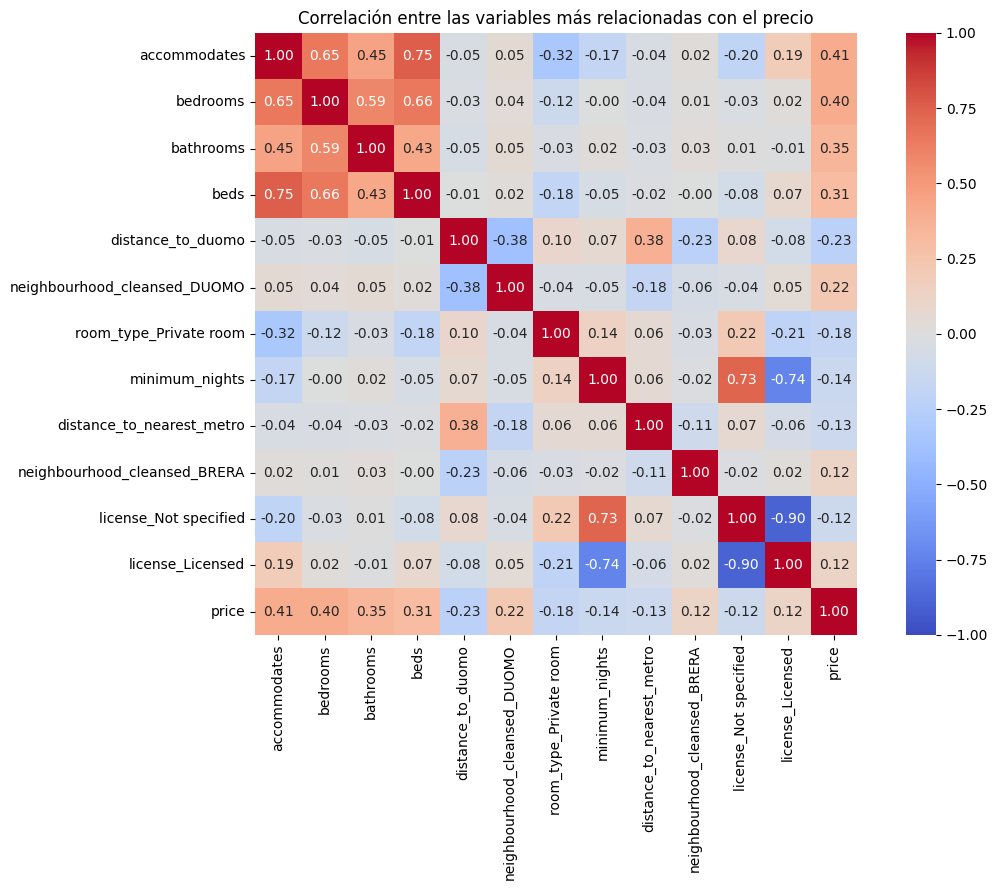

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

# Combinar variables predictoras y precio
datos_corr = X_train.copy()
datos_corr["price"] = y_train

# Seleccionar las variables numéricas más correlacionadas con el precio
corr_precio = datos_corr.corr(numeric_only=True)["price"].drop("price")
top_vars = corr_precio.abs().nlargest(12).index.tolist()

# Incluir el precio en la matriz
vars_grafico = top_vars + ["price"]
matriz_corr = datos_corr[vars_grafico].corr()

# Graficar
plt.figure(figsize=(12, 9))
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Correlación entre las variables más relacionadas con el precio")
plt.tight_layout()
plt.show()

Text(0, 0.5, 'Precio (€)')

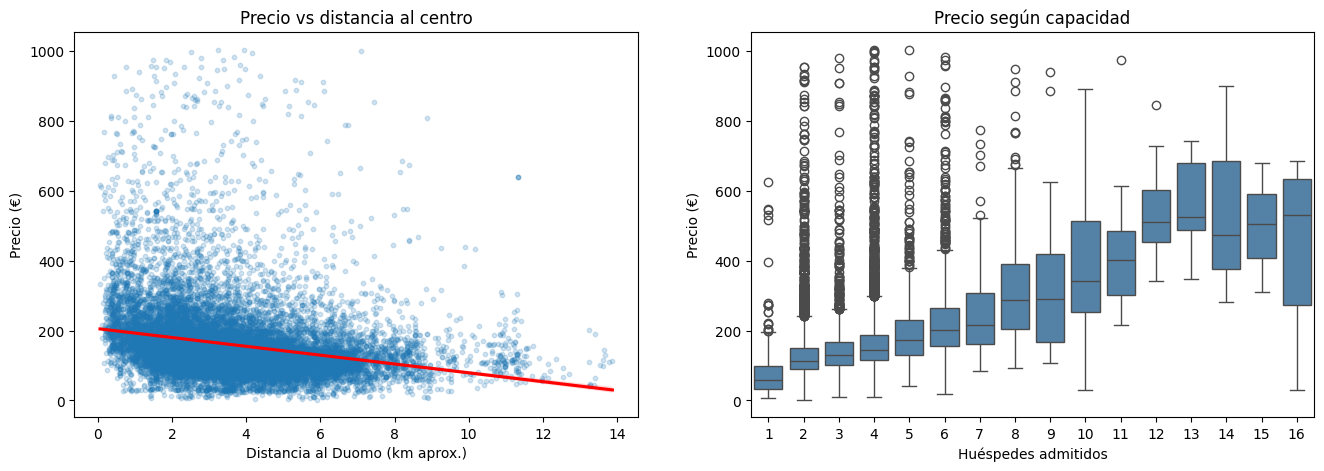

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Precio vs distancia (pasada a km)
sns.regplot(x=X_train["distance_to_duomo"] * 111, y=y_train,
            scatter_kws={"alpha": 0.2, "s": 10}, line_kws={"color": "red"}, ax=axes[0])
axes[0].set_xlabel("Distancia al Duomo (km aprox.)")
axes[0].set_title("Precio vs distancia al centro")

# Precio vs capacidad
sns.boxplot(x=X_train["accommodates"].astype(int), y=y_train, ax=axes[1], color="steelblue")
axes[1].set_title("Precio según capacidad")
axes[1].set_xlabel("Huéspedes admitidos")
axes[0].set_ylabel("Precio (€)")
axes[1].set_ylabel("Precio (€)")

### Modelo 1 – Regresión Lineal:

Para comparar qué variables influyen más, primero estandarizamos (media 0 y desvío 1). Si no, los coeficientes dependen de las unidades de cada variable y no se pueden comparar.

In [51]:
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)   # fit solo con train
X_test_esc = scaler.transform(X_test)

modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train_esc, y_train)

print("Intercepto:", round(modelo_lineal.intercept_, 2))

resultados_lineal = evaluar(modelo_lineal, "Regresión Lineal", X_train_esc, X_test_esc)
resultados_lineal

Intercepto: 160.4


,Modelo,Conjunto,R2,MSE,RMSE
0,Regresión Lineal,Train,0.352,7295.989,85.417
1,Regresión Lineal,Test,0.354,7527.983,86.764


Variables más influyentes

In [52]:
coeficientes = pd.DataFrame({
    "variable": X_train.columns,
    "coeficiente": modelo_lineal.coef_,
    "efecto_por_unidad": modelo_lineal.coef_ / scaler.scale_,
})
coeficientes["abs"] = coeficientes["coeficiente"].abs()
top = coeficientes.sort_values("abs", ascending=False).head(15)
top[["variable", "coeficiente", "efecto_por_unidad"]]

,variable,coeficiente,efecto_por_unidad
32,distance_to_duomo,-24.258115,-1369.654337
6,accommodates,20.290848,12.868052
8,bedrooms,20.170250,35.025489
7,bathrooms,15.620810,35.437168
55,neighbourhood_cleansed_DUOMO,13.045896,50.719126
10,minimum_nights,-12.499498,-0.946136
4,latitude,11.995296,583.384001
12,availability_30,9.580042,0.987238
28,reviews_per_month,-8.903291,-4.622672
19,estimated_occupancy_l365d,-8.863036,-0.104333


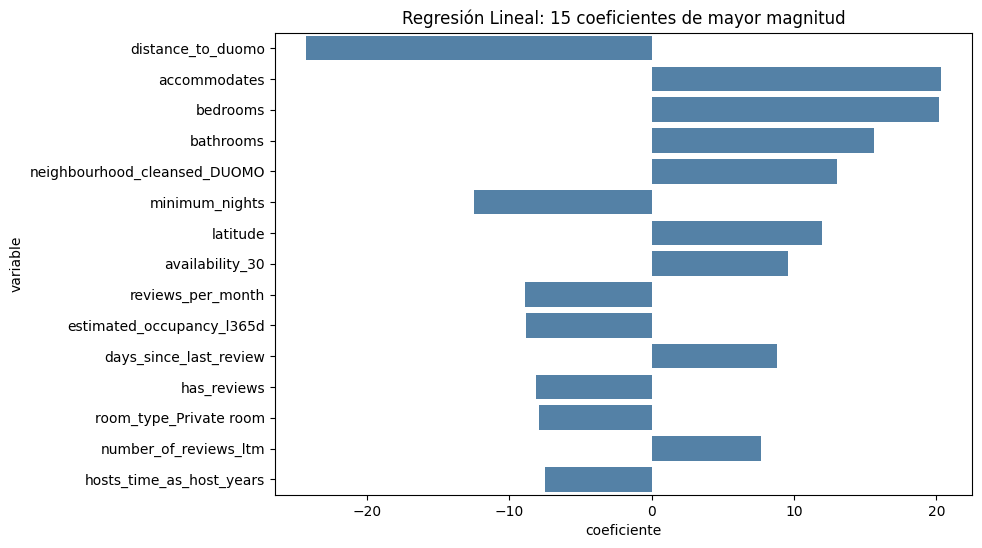

In [53]:
plt.figure(figsize=(9, 6))
sns.barplot(data=top, x="coeficiente", y="variable", color="steelblue")
plt.title("Regresión Lineal: 15 coeficientes de mayor magnitud")
plt.show()

#### Interpretación de los coeficientes
Como las variables predictoras están estandarizadas, los coeficientes permiten comparar la magnitud de sus asociaciones con el precio. Para facilitar la interpretación, también se calculó el efecto estimado en euros por unidad de las variables originales.
- Ubicación: la distancia al Duomo presenta una asociación negativa con el precio: los alojamientos más alejados tienden a tener precios menores. Por su parte, estar en el barrio Duomo se asocia con un precio estimado mayor respecto del barrio de referencia.
- Tamaño: el número de dormitorios, baños y huéspedes admitidos presenta asociaciones positivas con el precio. Esto sugiere que los alojamientos más grandes o con mayor capacidad tienden a tener tarifas más elevadas.
- Tipo de alojamiento: las habitaciones privadas presentan un precio estimado menor que los alojamientos enteros, tomando estos últimos como categoría de referencia.
- Estadía mínima y actividad: el número mínimo de noches, la frecuencia de reseñas y la ocupación estimada presentan asociaciones negativas con el precio. Esto podría reflejar diferencias entre alojamientos orientados a estadías cortas y largas, así como diferencias de demanda.
- Variables de reseñas: las variables que representan la existencia y antigüedad de las reseñas deben interpretarse con cautela, ya que la ausencia de reseñas no equivale a una antigüedad de cero días ni a un tiempo real de −1 días.
En conjunto, el modelo sugiere que la ubicación y las características físicas del alojamiento son factores relevantes para explicar las diferencias de precios por noche en Milán. Estas asociaciones no implican causalidad.

#### Desempeño

El modelo obtuvo un \(R^2 = 0,354\) en test, lo que significa que explica aproximadamente el 35,4 % de la variabilidad de los precios por noche. Su capacidad explicativa es moderada.

El RMSE en test fue de 86,76 €, lo que indica un error de predicción de alrededor de 87 € por noche. Es una magnitud considerable, aunque su importancia depende del rango de precios de los alojamientos.

Por último, los resultados de entrenamiento y prueba son similares: el \(R^2\) pasa de 0,352 a 0,354 y el RMSE de 85,42 € a 86,76 €. Esto sugiere que no hay indicios claros de sobreajuste y que el modelo generaliza de forma similar a datos no utilizados durante el entrenamiento.

### Modelo 2 - Random Forest:

#### Real vs predicho

El gráfico compara los precios reales con los predichos en el conjunto de prueba. El modelo ajusta razonablemente los alojamientos de hasta unos 300 €, pero subestima sistemáticamente los de mayor precio y genera algunas predicciones negativas. Además, el error aumenta a medida que crece el precio.

Esto indica que el segmento de precios altos depende de factores no capturados por las variables disponibles o de relaciones no lineales, lo que motiva la evaluación de Random Forest.

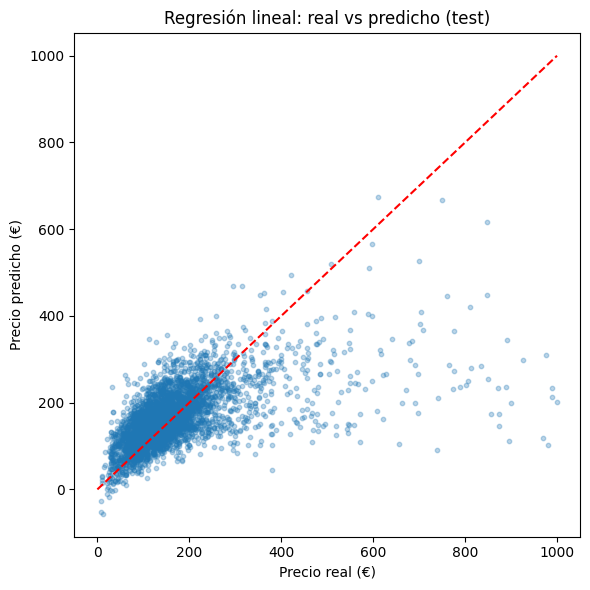

In [54]:
fig, ax = plt.subplots(figsize=(6, 6))

# Real vs predicho
y_pred = modelo_lineal.predict(X_test_esc)
ax.scatter(y_test, y_pred, alpha=0.3, s=10)
lim = [0, max(y_test.max(), y_pred.max())]
ax.plot(lim, lim, "r--")
ax.set_xlabel("Precio real (€)")
ax.set_ylabel("Precio predicho (€)")
ax.set_title("Regresión lineal: real vs predicho (test)")

plt.tight_layout()
plt.savefig("real_vs_predicho_lineal.png", dpi=200, bbox_inches="tight")
plt.show()

Elegimos Random Forest porque la regresión lineal explicó solo el 35% de la variabilidad del precio, lo que sugiere relaciones no lineales. Este modelo combina muchos árboles de decisión, lo que le permite captar relaciones no lineales e interacciones entre variables (por ejemplo, el efecto de la cantidad de huéspedes según el tipo de alojamiento). Además, es poco sensible a outliers, no requiere escalar las variables y, al promediar muchos árboles, sobreajusta menos que un único árbol.

#### Optimización de hiperparámetros

In [55]:
param_grid = {
    "n_estimators": [100],
    "max_depth": [15, 25],
    "min_samples_leaf": [2, 5],
}

busqueda = GridSearchCV(
    RandomForestRegressor(
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),
    param_grid,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    verbose=1
)

busqueda.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda.best_params_)
print("RMSE promedio en CV:", round(-busqueda.best_score_, 3))

mejor_rf = busqueda.best_estimator_

resultados_rf = evaluar(mejor_rf, "Random Forest", X_train, X_test)
display(resultados_rf)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Mejores hiperparámetros: {'max_depth': 25, 'min_samples_leaf': 2, 'n_estimators': 100}
RMSE promedio en CV: 82.041


,Modelo,Conjunto,R2,MSE,RMSE
0,Random Forest,Train,0.775,2531.471,50.314
1,Random Forest,Test,0.415,6811.939,82.534


Variables más influyentes

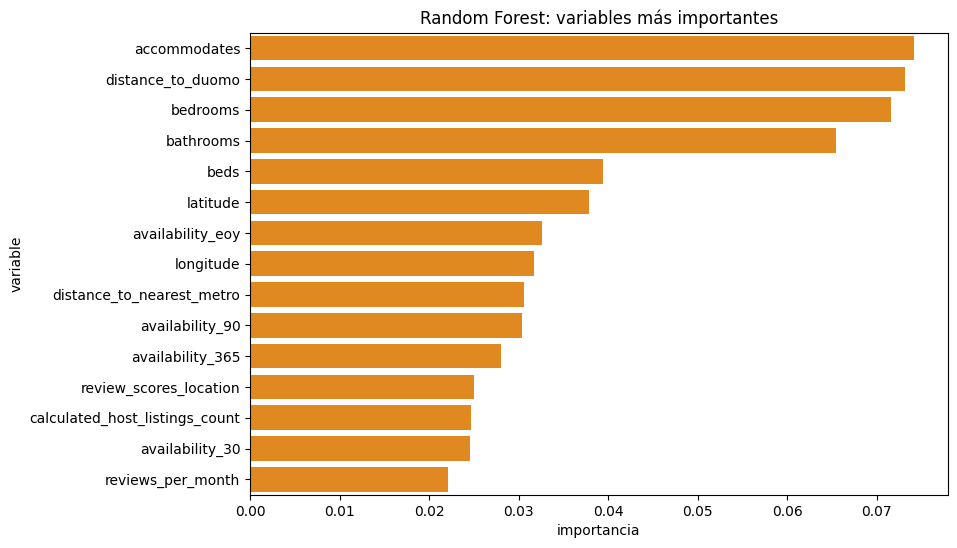

In [56]:
importancias = pd.DataFrame({
    "variable": X_train.columns,
    "importancia": mejor_rf.feature_importances_,
}).sort_values("importancia", ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(data=importancias, x="importancia", y="variable", color="darkorange")
plt.title("Random Forest: variables más importantes")
plt.show()

#### Desempeño

La mejor combinación fue max_depth = 25 y min_samples_leaf = 2, con un RMSE promedio en CV de 82,0 €. En test el modelo obtiene un R² de 0.415 y un RMSE de 82,5 €, mejor que la regresión lineal (0.354 y 86,8 €).

En train alcanza un R² de 0.775 y un RMSE de 50,3 €, lo que muestra cierto sobreajuste, esperable en este tipo de modelos. Aun así, el RMSE en test es casi igual al obtenido en la validación cruzada, lo que indica que la estimación fue confiable y que el modelo generaliza de forma consistente.

Como los mejores valores de los hiperparámetros quedaron en el límite de la grilla explorada, podría ser útil probar árboles más profundos. Sin embargo, no se amplió la búsqueda debido al costo computacional.

### Comparación
   ¿Qué modelo elegiríamos?

In [57]:
comparacion = pd.concat([resultados_lineal, resultados_rf], ignore_index=True)

cuadro = comparacion.pivot(index="Modelo", columns="Conjunto", values=["R2", "RMSE"])
cuadro.columns = [f"{metrica} {conjunto}" for metrica, conjunto in cuadro.columns]
cuadro = cuadro[["R2 Train", "R2 Test", "RMSE Train", "RMSE Test"]]
cuadro

,R2 Train,R2 Test,RMSE Train,RMSE Test
Modelo,,,,
Random Forest,0.775,0.415,50.314,82.534
Regresión Lineal,0.352,0.354,85.417,86.764


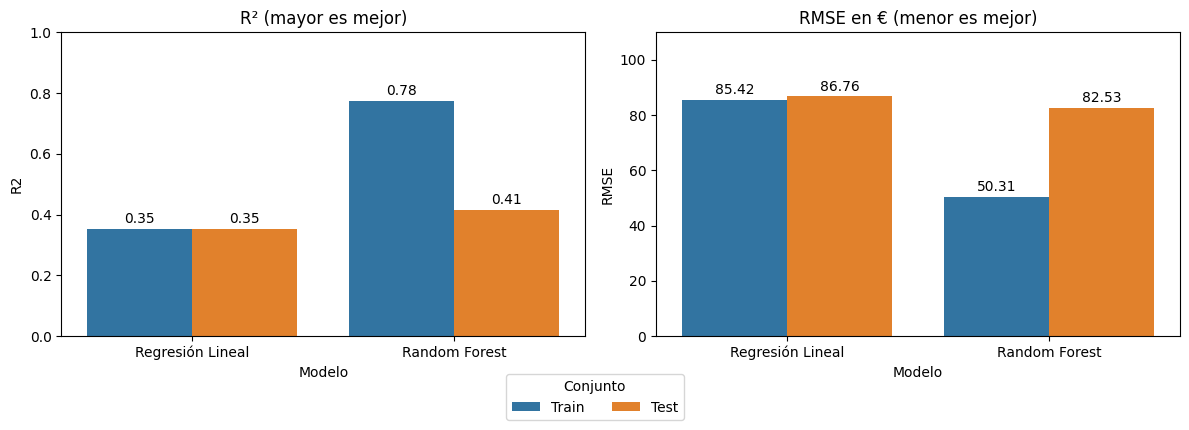

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=comparacion, x="Modelo", y="R2", hue="Conjunto", ax=axes[0])
axes[0].set_title("R² (mayor es mejor)")
axes[0].set_ylim(0, 1)

sns.barplot(data=comparacion, x="Modelo", y="RMSE", hue="Conjunto", ax=axes[1])
axes[1].set_title("RMSE en € (menor es mejor)")
axes[1].set_ylim(0, 110)

for ax in axes:
    for barras in ax.containers:
        ax.bar_label(barras, fmt="%.2f", padding=2)
    ax.get_legend().remove()

# Una sola leyenda, debajo de los dos gráficos
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Conjunto", loc="lower center", ncol=2,
           bbox_to_anchor=(0.5, -0.08))

plt.tight_layout()
plt.show()

Elegiríamos el Random Forest para predecir el precio de alquiler por noche en Milán, ya que obtiene un mejor desempeño en el conjunto de prueba, que permite evaluar cómo funciona el modelo con datos no utilizados durante el entrenamiento. Explica un 41,5% de la variabilidad del precio ($R^2 = 0,415$), frente al 35,4% de la regresión lineal, y reduce el RMSE de 86,8 € a 82,5 € por noche.

La regresión lineal tiene la ventaja de ser más interpretable, ya que sus coeficientes permiten analizar cuánto y en qué sentido se relaciona cada variable con el precio. Por eso resulta útil para comprender el problema, aunque su capacidad predictiva es menor.

El Random Forest, en cambio, puede capturar relaciones no lineales e interacciones entre variables. Si bien presenta cierto sobreajuste ($R^2 = 0{,}775$ en train frente a $0{,}415$ en test), obtiene mejores resultados en datos no vistos y su RMSE en test es muy similar al estimado mediante validación cruzada.

De todas formas, ninguno de los dos modelos explica más de la mitad de la variabilidad de los precios, y un RMSE de aproximadamente 80 € por noche sigue siendo considerable. Cabe aclarar que el RMSE no es exactamente el error promedio, sino la raíz del promedio de los errores al cuadrado, por lo que penaliza más los errores grandes.